# Notebook 04 — Training Protocol and Hyperparameter Selection

**Track A · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (project level)** | When identity and context point to different actions, what does a trained model do? Track A trains and freezes the model. |
| **Purpose of this notebook** | (1) Define one controlled training procedure used for every neural model in Track A. (2) Run a pilot to check the epoch budget. (3) Select the learning rate and weight decay with a small, pre-defined search on validation data. (4) Train the MLP baseline B4. |
| **Base configuration** | 4 layers, 4 heads, d_model 128, d_ff 512, context K = 32, player encoding T100. The architecture and the encoding are compared in notebook 05. |
| **Test data** | Not used. All selections are made on the validation split. |


In [2]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every Track A notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# PROJECT_DIR holds code (src/), data artifacts, runs, results and the release.
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
# DATASET_PATH is the prepared research dataset (one row per on-ball event).
DATASET_PATH = Path(os.environ.get("TRACK_A_DATASET", str(PROJECT_DIR / "data" / "cleaned_dataset.parquet")))
# RUN_MODE = "full"  -> real research runs (use this for every reported number)
# RUN_MODE = "smoke" -> tiny code check only; outputs go to PROJECT_DIR/smoke and are NOT results
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "src").mkdir(exist_ok=True)
(PROJECT_DIR / "tests").mkdir(exist_ok=True)

# Data-audit artifacts are cheap and always produced in full mode.
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
# Training runs, results and figures are separated by run mode so a smoke check can never
# overwrite or be confused with a research result.
OUTPUT_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
RUNS_DIR = OUTPUT_DIR / "runs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
for folder in [ARTIFACTS_DIR, RUNS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH, "| exists:", DATASET_PATH.exists())

Mounted at /content/drive
Colab: True | RUN_MODE: full
PROJECT_DIR: /content/drive/MyDrive/soccer_mi/track_a
DATASET_PATH: /content/drive/MyDrive/soccer_mi/track_a/data/cleaned_dataset.parquet | exists: True


## 1. Training terms

| Term | Meaning |
|---|---|
| **Seed** | The number that initialises the random number generators. The same seed gives the same initial weights and the same order of training examples, so a run can be reproduced exactly. Different seeds show how much results vary by chance. |
| **Batch** | The group of windows processed together before one weight update (here 256 windows = 8,192 predictions). |
| **Step** | One weight update. **Epoch**: one pass over all 63,787 training windows (250 steps). |
| **Optimizer (AdamW)** | The rule that turns gradients into weight updates. Adam adapts the step size of each weight to the history of its gradients; the "W" means weight decay is applied separately from the gradient step. |
| **Learning rate** | How large each update is. Too high: training is unstable. Too low: training is slow or stalls. |
| **Warm-up and cosine schedule** | The learning rate rises linearly from almost 0 to its peak over the first 5% of steps (large updates on random initial weights can be unstable), then follows half a cosine curve down to 10% of the peak. |
| **Weight decay** | Pulls weight-matrix values slightly towards zero at each step, a form of regularisation (discouraging overly large weights, which reduces overfitting). Applied only to the matrices of linear layers — not to embedding tables, LayerNorm or biases, whose meaning would be distorted by shrinking. |
| **Gradient clipping** | If the overall size (norm) of the gradient exceeds 1.0, it is scaled down to 1.0. Prevents a single unusual batch from causing a huge update. |
| **Early stopping** | Training stops if validation NLL has not improved for 5 consecutive epochs. The checkpoint with the best validation NLL is kept. |
| **Checkpoint** | A saved copy of the model weights (and, for resuming, the optimizer state). |
| **Overfitting / underfitting** | Overfitting: training loss keeps falling while validation loss rises (the model memorises training matches). Underfitting: both stay high. |

## 2. The training module

The functions below are written to `src/training.py` and used by every neural model in notebooks 04–06, so all models are trained under exactly the same procedure.

### 2.1 Reproducibility, schedule and optimizer

In [3]:
%%writefile src/training.py
"""
src/training.py — one controlled training procedure for every neural model (notebook 04).
"""
import json
import math
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch

import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline

DEFAULT_TRAINING = {
    "batch_size": 256,
    "max_epochs": 30,
    "warmup_fraction": 0.05,
    "min_lr_ratio": 0.1,
    "grad_clip": 1.0,
    "patience": 5,
    "beta1": 0.9,
    "beta2": 0.999,
    "eps": 1e-8,
    "learning_rate": 3e-4,
    "weight_decay": 0.1,
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def configure_determinism():
    """Ask PyTorch for deterministic kernels (warn instead of fail if one is unavailable)."""
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False


def environment_info():
    info = {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "platform": platform.platform(),
        "cuda_available": torch.cuda.is_available(),
    }
    if torch.cuda.is_available():
        info["gpu"] = torch.cuda.get_device_name(0)
        info["cuda"] = torch.version.cuda
    return info


def learning_rate_at_step(step, total_steps, peak_lr, warmup_steps, min_lr_ratio):
    """Linear warm-up to peak_lr, then cosine decay to min_lr_ratio * peak_lr."""
    if step < warmup_steps:
        return peak_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    progress = min(progress, 1.0)
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return peak_lr * (min_lr_ratio + (1.0 - min_lr_ratio) * cosine)


def make_optimizer(model, training):
    """AdamW. Weight decay only on 2-D weight matrices outside the input embedding module."""
    decay_parameters = []
    no_decay_parameters = []
    for name, parameter in model.named_parameters():
        is_input_encoding = name.startswith("embedding.")
        if parameter.ndim == 2 and not is_input_encoding:
            decay_parameters.append(parameter)
        else:
            no_decay_parameters.append(parameter)
    groups = [
        {"params": decay_parameters, "weight_decay": training["weight_decay"]},
        {"params": no_decay_parameters, "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(groups, lr=training["learning_rate"],
                             betas=(training["beta1"], training["beta2"]), eps=training["eps"])

Overwriting src/training.py


### 2.2 Data bundles and the protected test split

A *data bundle* holds everything a run needs for one encoding and one context length: the encoded inputs, the training windows, and the evaluation views (each event scored once, see notebook 01).

**The test split is locked.** The prediction function refuses to score the test split unless the model configuration has been frozen and the test split has been unlocked explicitly (notebook 06). Every access is logged. This keeps all selection decisions on validation data.

In [4]:
%%writefile -a src/training.py

_DATA_CACHE = {}


def prepare_data(events, artifacts_dir, encoding_name, possession_features, context_length, stride,
                 device, run_mode="full"):
    """Encode inputs and build windows/evaluation views for one (encoding, context length)."""
    key = (encoding_name, possession_features, context_length, stride, str(device), run_mode)
    if key in _DATA_CACHE:
        return _DATA_CACHE[key]

    encoding = data.load_encoding(Path(artifacts_dir) / "encodings" / encoding_name)
    assert encoding["n_events"] == len(events), "encoding was built for a different event table"
    features, vocabulary_sizes = data.encode_features(events, encoding, possession_features)
    targets = events["action_id"].to_numpy().astype("int64")
    encoded = batching.EncodedData(features, targets, device)

    train_windows = data.build_windows(events, context_length, stride, split="train")
    views = {}
    for split in ["train", "val"]:
        views[split] = data.build_evaluation_view(events, split, context_length, stride)

    if run_mode == "smoke":
        # small, fixed subsets: code check only
        train_windows = train_windows[:512]
        # the subset is defined by EVENTS (first two validation match-periods), so that every
        # context length scores exactly the same events
        val_view = views["val"]
        period_key = (events["match_id"].to_numpy()[val_view["event_rows"]] * 10
                      + events["period"].to_numpy()[val_view["event_rows"]])
        first_two = np.unique(period_key)[:2]
        keep_events = np.isin(period_key, first_two)
        keep_windows = np.unique(val_view["window_index"][keep_events])
        new_window_index = np.searchsorted(keep_windows, val_view["window_index"][keep_events])
        small_view = {"windows": val_view["windows"][keep_windows],
                      "event_rows": val_view["event_rows"][keep_events],
                      "window_index": new_window_index,
                      "position": val_view["position"][keep_events]}
        views["val"] = small_view
        views["train"] = small_view
        views["test"] = small_view          # never real test data in smoke mode

    bundle = {
        "encoding_name": encoding_name,
        "possession_features": possession_features,
        "context_length": context_length,
        "stride": stride,
        "run_mode": run_mode,
        "vocabulary_sizes": vocabulary_sizes,
        "encoded": encoded,
        "targets": targets,
        "match_ids": events["match_id"].to_numpy(),
        "train_windows": torch.as_tensor(train_windows, device=device),
        "views": views,
        "events": events,
        "artifacts_dir": str(artifacts_dir),
        "test_unlocked": run_mode == "smoke",
        "device": device,
    }
    _DATA_CACHE[key] = bundle
    return bundle


def unlock_test_split(bundle, output_dir, events):
    """Allow test evaluation ONLY after the configuration is frozen. Logs every unlock."""
    frozen_path = Path(output_dir) / "config" / "frozen_config.json"
    if not frozen_path.exists():
        raise RuntimeError("Test split is locked: freeze the configuration (notebook 05) first.")
    if bundle["run_mode"] == "full" and "test" not in bundle["views"]:
        bundle["views"]["test"] = data.build_evaluation_view(events, "test", bundle["context_length"], bundle["stride"])
    bundle["test_unlocked"] = True
    log_path = Path(output_dir) / "logs" / "test_access_log.jsonl"
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with open(log_path, "a") as handle:
        handle.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(),
                                 "frozen_config": str(frozen_path),
                                 "encoding": bundle["encoding_name"]}) + "\n")


@torch.no_grad()
def predict_view(model, bundle, split, batch_size=512):
    """Logits for every event of a split, each event scored once. Returns (logits, targets, event_rows)."""
    if split == "test" and not bundle["test_unlocked"]:
        raise RuntimeError("Test split is locked.")
    view = bundle["views"][split]
    windows = torch.as_tensor(view["windows"], device=bundle["device"])
    model.eval()
    window_logits = []
    for start in range(0, len(windows), batch_size):
        inputs, _ = bundle["encoded"].batch(windows[start:start + batch_size])
        window_logits.append(model(inputs).float().cpu())
    window_logits = torch.cat(window_logits, dim=0)                      # [n_windows, T, C]
    window_index = torch.as_tensor(view["window_index"])
    position = torch.as_tensor(view["position"])
    event_logits = window_logits[window_index, position].numpy()         # [n_events, C]
    event_rows = view["event_rows"]
    return event_logits, bundle["targets"][event_rows], event_rows

Appending to src/training.py


### 2.3 One training run

`train_run` is the only function that trains a neural model in Track A. For each epoch it:

1. shuffles the training windows with a generator seeded by (seed, epoch), so the order is reproducible even after resuming;
2. for each batch: sets the scheduled learning rate, computes the loss at all 32 positions, back-propagates, clips the gradient norm at 1.0 and updates the weights;
3. evaluates validation NLL, accuracy and macro-F1 on the one-prediction-per-event view;
4. saves `last.pt` (for resuming) and, if validation NLL improved, `best.pt`;
5. stops early after 5 epochs without improvement, or immediately if the loss becomes non-finite (recorded as *diverged*).

At the end it reloads the best checkpoint, saves validation predictions and per-event training NLL (used to measure overfitting), and writes `final_results.json` plus one line in the experiment manifest.

In [5]:
%%writefile -a src/training.py

def build_model(run_config, vocabulary_sizes):
    model_settings = dict(run_config["model"])
    model_settings["context_length"] = run_config["context_length"]
    if run_config["model_type"] == "transformer":
        config = model_module.ModelConfig(vocabulary_sizes=vocabulary_sizes, **model_settings)
        return model_module.EventTransformer(config)
    if run_config["model_type"] == "mlp":
        hidden = model_settings.pop("hidden", 512)
        n_previous = model_settings.pop("n_previous", 3)
        config = model_module.ModelConfig(vocabulary_sizes=vocabulary_sizes, **model_settings)
        return mlp_baseline.PreviousEventsMLP(config, n_previous=n_previous, hidden=hidden)
    raise ValueError(run_config["model_type"])


def run_name_for(run_config):
    """A readable name that encodes every setting that differs between runs."""
    model = run_config["model"]
    training = run_config["training"]
    groups = model.get("use_groups", model_module.ALL_GROUPS)
    if list(groups) == list(model_module.ALL_GROUPS):
        group_tag = "all"
    else:
        group_tag = "+".join(groups)
    name = (f"{run_config['model_type']}_{run_config['encoding']}_{run_config['possession_features']}"
            f"_L{model.get('n_layers', 4)}_H{model.get('n_heads', 4)}_D{model.get('d_model', 128)}"
            f"_F{model.get('d_ff', 512)}_K{run_config['context_length']}_g-{group_tag}"
            f"_lr{training['learning_rate']:g}_wd{training['weight_decay']:g}_s{run_config['seed']}")
    return name


def save_json(path, content):
    with open(path, "w") as handle:
        json.dump(content, handle, indent=2, default=str)


def train_run(run_config, bundle, runs_dir, manifest_path, keep_every_epoch=False, verbose=True):
    """Train one model (or load it if already finished). Returns final_results dict."""
    run_name = run_name_for(run_config)
    run_dir = Path(runs_dir) / run_name
    final_path = run_dir / "final_results.json"
    if final_path.exists():
        with open(final_path) as handle:
            return json.load(handle)
    run_dir.mkdir(parents=True, exist_ok=True)
    save_json(run_dir / "run_config.json", run_config)

    training = dict(DEFAULT_TRAINING)
    training.update(run_config["training"])
    if bundle["run_mode"] == "smoke":
        training["max_epochs"] = min(training["max_epochs"], 2)
    device = bundle["device"]
    seed = run_config["seed"]

    configure_determinism()
    set_seed(seed)
    model = build_model(run_config, bundle["vocabulary_sizes"]).to(device)
    optimizer = make_optimizer(model, training)

    train_windows = bundle["train_windows"]
    n_windows = len(train_windows)
    steps_per_epoch = math.ceil(n_windows / training["batch_size"])
    total_steps = steps_per_epoch * training["max_epochs"]
    warmup_steps = max(1, round(training["warmup_fraction"] * total_steps))

    state = {"epoch": 0, "step": 0, "best_val_nll": float("inf"), "best_epoch": -1,
             "epochs_without_improvement": 0, "diverged": False, "elapsed_seconds": 0.0}
    last_path = run_dir / "last.pt"
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        state = checkpoint["state"]
        if verbose:
            print(f"[{run_name}] resuming after epoch {state['epoch']}")

    history_path = run_dir / "history.csv"
    while (state["epoch"] < training["max_epochs"]
           and state["epochs_without_improvement"] < training["patience"]
           and not state["diverged"]):
        epoch_start = time.time()
        generator = torch.Generator().manual_seed(seed * 1000 + state["epoch"])
        order = torch.randperm(n_windows, generator=generator).to(device)
        model.train()
        loss_sum = 0.0
        gradient_norm_sum = 0.0
        clipped_steps = 0
        batches = 0
        learning_rate = 0.0
        for batch_start in range(0, n_windows, training["batch_size"]):
            batch_ids = order[batch_start:batch_start + training["batch_size"]]
            inputs, targets = bundle["encoded"].batch(train_windows[batch_ids])

            learning_rate = learning_rate_at_step(state["step"], total_steps, training["learning_rate"],
                                                  warmup_steps, training["min_lr_ratio"])
            for group in optimizer.param_groups:
                group["lr"] = learning_rate

            logits = model(inputs)
            loss = model_module.compute_loss(logits, targets)
            if not torch.isfinite(loss):
                state["diverged"] = True
                break
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), training["grad_clip"]).item()
            optimizer.step()

            state["step"] += 1
            loss_sum += loss.item()
            gradient_norm_sum += gradient_norm
            if gradient_norm > training["grad_clip"]:
                clipped_steps += 1
            batches += 1
        if state["diverged"]:
            break

        val_logits, val_targets, _ = predict_view(model, bundle, "val")
        val_metrics = metrics.compute_metrics(val_logits, val_targets)
        epoch_seconds = time.time() - epoch_start
        state["elapsed_seconds"] += epoch_seconds
        state["epoch"] += 1

        row = {"epoch": state["epoch"], "step": state["step"], "learning_rate": learning_rate,
               "train_loss": loss_sum / batches, "val_nll": val_metrics["nll"],
               "val_accuracy": val_metrics["accuracy"], "val_macro_f1": val_metrics["macro_f1"],
               "mean_gradient_norm": gradient_norm_sum / batches,
               "clipped_fraction": clipped_steps / batches, "epoch_seconds": epoch_seconds}
        pd.DataFrame([row]).to_csv(history_path, mode="a", header=not history_path.exists(), index=False)

        if val_metrics["nll"] < state["best_val_nll"]:
            state["best_val_nll"] = val_metrics["nll"]
            state["best_epoch"] = state["epoch"]
            state["epochs_without_improvement"] = 0
            torch.save(model.state_dict(), run_dir / "best.pt")
        else:
            state["epochs_without_improvement"] += 1
        if keep_every_epoch:
            torch.save(model.state_dict(), run_dir / f"epoch_{state['epoch']:03d}.pt")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "state": state}, last_path)
        if verbose:
            print(f"[{run_name}] epoch {state['epoch']:2d} | train loss {row['train_loss']:.4f} | "
                  f"val NLL {row['val_nll']:.4f} | val acc {row['val_accuracy']:.4f} | "
                  f"val macro-F1 {row['val_macro_f1']:.4f} | {epoch_seconds:.0f}s")

    return finalise_run(run_config, run_name, run_dir, model, bundle, training, state, manifest_path)


def finalise_run(run_config, run_name, run_dir, model, bundle, training, state, manifest_path):
    if (run_dir / "best.pt").exists():
        model.load_state_dict(torch.load(run_dir / "best.pt", map_location=bundle["device"]))
    val_logits, val_targets, val_rows = predict_view(model, bundle, "val")
    np.savez_compressed(run_dir / "val_predictions.npz", logits=val_logits.astype("float32"), event_rows=val_rows)
    train_logits, train_targets, train_rows = predict_view(model, bundle, "train")
    train_nll = metrics.per_event_nll(train_logits, train_targets)
    np.savez_compressed(run_dir / "train_event_nll.npz", nll=train_nll.astype("float32"), event_rows=train_rows)

    if run_config["model_type"] == "transformer":
        parameter_counts = model_module.count_parameters(model)
    else:
        parameter_counts = {"total": sum(p.numel() for p in model.parameters())}
    final_results = {
        "run_name": run_name,
        "run_config": run_config,
        "training_settings": training,
        "run_mode": bundle["run_mode"],
        "best_epoch": state["best_epoch"],
        "epochs_run": state["epoch"],
        "stopped_early": state["epochs_without_improvement"] >= training["patience"],
        "diverged": state["diverged"],
        "runtime_seconds": state["elapsed_seconds"],
        "val_metrics": metrics.compute_metrics(val_logits, val_targets),
        "train_nll": float(train_nll.mean()),
        "parameter_counts": parameter_counts,
        "environment": environment_info(),
        "finished_at": datetime.now(timezone.utc).isoformat(),
    }
    save_json(run_dir / "final_results.json", final_results)
    manifest_entry = {"run_name": run_name, "run_dir": str(run_dir), "seed": run_config["seed"],
                      "encoding": run_config["encoding"], "model_type": run_config["model_type"],
                      "model": run_config["model"], "context_length": run_config["context_length"],
                      "training": training, "best_epoch": state["best_epoch"],
                      "val_nll": final_results["val_metrics"]["nll"],
                      "parameters": parameter_counts.get("total"), "run_mode": bundle["run_mode"],
                      "finished_at": final_results["finished_at"]}
    Path(manifest_path).parent.mkdir(parents=True, exist_ok=True)
    with open(manifest_path, "a") as handle:
        handle.write(json.dumps(manifest_entry, default=str) + "\n")
    return final_results


def load_trained_model(run_dir, bundle):
    with open(Path(run_dir) / "run_config.json") as handle:
        run_config = json.load(handle)
    model = build_model(run_config, bundle["vocabulary_sizes"]).to(bundle["device"])
    model.load_state_dict(torch.load(Path(run_dir) / "best.pt", map_location=bundle["device"]))
    model.eval()
    return model

Appending to src/training.py


### 2.4 The MLP baseline (B4)

**Question it answers.** Is attention over the whole window needed, or is a fixed short history enough?

**Input.** The same factorised event vectors as the Transformer (same embedding code, but without position vectors), for the current event and the **three previous** events, concatenated into one 512-number vector. Where fewer than three previous events exist in the window, zeros stand for "no event".

**Architecture.** 512 → 512 → 512 → 15 with GELU, about 0.8 million parameters — similar in size to the Transformer, so a difference between them reflects the architecture rather than the number of parameters. It predicts at every position, so it uses exactly the same training loop and evaluation view.

In [6]:
%%writefile src/mlp_baseline.py
"""
src/mlp_baseline.py — B4: MLP over the current event and the n previous events (notebook 04).
"""
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

import src.model as model_module


class PreviousEventsMLP(nn.Module):
    def __init__(self, config, n_previous=3, hidden=512):
        super().__init__()
        embedding_config = copy.deepcopy(config)
        embedding_config.use_position = False          # order is given by concatenation instead
        self.config = embedding_config
        self.n_previous = n_previous
        self.embedding = model_module.FactorizedEventEmbedding(embedding_config)
        input_width = config.d_model * (n_previous + 1)
        self.layer_1 = nn.Linear(input_width, hidden)
        self.layer_2 = nn.Linear(hidden, hidden)
        self.output_layer = nn.Linear(hidden, config.n_actions)

    def forward(self, inputs):
        event_vectors, _ = self.embedding(inputs)                         # [B, T, D]
        pieces = [event_vectors]
        for lag in range(1, self.n_previous + 1):
            shifted = torch.zeros_like(event_vectors)
            shifted[:, lag:] = event_vectors[:, :-lag]                    # event t-lag, zeros if absent
            pieces.append(shifted)
        combined = torch.cat(pieces, dim=-1)                              # [B, T, D * (n_previous + 1)]
        hidden = F.gelu(self.layer_1(combined))
        hidden = F.gelu(self.layer_2(hidden))
        return self.output_layer(hidden)                                  # [B, T, C]

Overwriting src/mlp_baseline.py


### 2.5 Comparing conditions: the decision rule

Several decisions in notebooks 04–06 ask whether condition A is **better than B beyond noise**. There are two sources of noise:

* **data noise** — a different sample of matches would give a slightly different score;
* **training noise** — a different seed gives a slightly different model.

**Rule used in Track A.** A is better than B beyond noise if **both** hold:

1. **Data noise:** the 95% match-level bootstrap confidence interval of the NLL difference (A − B), computed on per-event NLL averaged over seeds, lies entirely below 0.
2. **Training noise:** every seed of A has lower validation NLL than every seed of B (complete separation of the seed results).

**Where the rule comes from.** The 95% level is the conventional confidence level; complete separation is the simplest seed-level criterion that needs no numerical tolerance. With 3 seeds per condition, complete separation happens by chance with probability 1/20 when two conditions are truly equal (the chance that the 3 lowest of 6 values all belong to one condition is 1 in 20), which matches the 95% level of criterion 1. No other numerical threshold is used.

The rule is a convention adopted for this study; it has not been compared with alternative decision rules.

**"Smallest configuration within noise of the best"** means: among candidates ordered from simplest to most complex, choose the first one that the best-scoring candidate does *not* beat beyond noise.

In [7]:
%%writefile src/analysis.py
"""
src/analysis.py — loading run results and comparing conditions (notebook 04).
"""
import json
from pathlib import Path

import numpy as np
import pandas as pd

import src.metrics as metrics


def load_final_results(run_dir):
    with open(Path(run_dir) / "final_results.json") as handle:
        return json.load(handle)


def load_val_event_nll(run_dir, targets):
    """Per-event validation NLL of a finished run, ordered by event row."""
    predictions = np.load(Path(run_dir) / "val_predictions.npz")
    rows = predictions["event_rows"]
    order = np.argsort(rows)
    nll = metrics.per_event_nll(predictions["logits"][order], targets[rows[order]])
    return rows[order], nll


def condition_event_nll(run_dirs, targets):
    """Per-event NLL for each seed of one condition. Returns (event_rows, [n_seeds, n_events])."""
    all_nll = []
    reference_rows = None
    for run_dir in run_dirs:
        rows, nll = load_val_event_nll(run_dir, targets)
        if reference_rows is None:
            reference_rows = rows
        assert np.array_equal(rows, reference_rows), "runs were evaluated on different events"
        all_nll.append(nll)
    return reference_rows, np.stack(all_nll)


def compare_conditions(runs_a, runs_b, targets, match_ids, event_mask=None, n_resamples=2000, seed=0):
    """Is A better (lower NLL) than B beyond noise? See notebook 04, Section 2.5."""
    rows_a, nll_a = condition_event_nll(runs_a, targets)
    rows_b, nll_b = condition_event_nll(runs_b, targets)
    assert np.array_equal(rows_a, rows_b)
    if event_mask is None:
        keep = np.ones(len(rows_a), dtype=bool)
    else:
        keep = event_mask[rows_a]
    seed_means_a = nll_a[:, keep].mean(axis=1)
    seed_means_b = nll_b[:, keep].mean(axis=1)
    difference = nll_a[:, keep].mean(axis=0) - nll_b[:, keep].mean(axis=0)
    interval = metrics.match_bootstrap_mean(difference, match_ids[rows_a][keep], n_resamples, seed)
    ci_below_zero = interval["ci_high"] < 0
    separated = seed_means_a.max() < seed_means_b.min()
    return {
        "n_events": int(keep.sum()),
        "nll_a_mean": float(seed_means_a.mean()), "nll_a_seed_sd": float(seed_means_a.std(ddof=1)) if len(seed_means_a) > 1 else 0.0,
        "nll_b_mean": float(seed_means_b.mean()), "nll_b_seed_sd": float(seed_means_b.std(ddof=1)) if len(seed_means_b) > 1 else 0.0,
        "difference_a_minus_b": interval["mean"],
        "difference_ci_low": interval["ci_low"], "difference_ci_high": interval["ci_high"],
        "seeds_completely_separated": bool(separated),
        "a_better_beyond_noise": bool(ci_below_zero and separated),
    }


def smallest_within_noise(candidates, targets, match_ids):
    """candidates: list of (label, run_dirs) ordered simplest -> most complex.

    Returns (chosen_label, table). The best candidate is the one with the lowest mean NLL;
    the chosen one is the first candidate the best does NOT beat beyond noise.
    """
    means = []
    for label, run_dirs in candidates:
        _, nll = condition_event_nll(run_dirs, targets)
        means.append(float(nll.mean(axis=1).mean()))
    best_position = int(np.argmin(means))
    best_label, best_runs = candidates[best_position]
    rows = []
    chosen = None
    for position, (label, run_dirs) in enumerate(candidates):
        if position == best_position:
            comparison = None
            beaten = False
        else:
            comparison = compare_conditions(best_runs, run_dirs, targets, match_ids)
            beaten = comparison["a_better_beyond_noise"]
        if chosen is None and not beaten:
            chosen = label
        row = {"candidate": label, "mean val NLL": round(means[position], 4),
               "is best": position == best_position, "best beats it beyond noise": beaten}
        if comparison is not None:
            row["best - candidate (CI)"] = (f"{comparison['difference_a_minus_b']:+.4f} "
                                            f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]")
            row["seeds separated"] = comparison["seeds_completely_separated"]
        rows.append(row)
    return chosen, pd.DataFrame(rows).set_index("candidate")


def seed_summary(run_dirs):
    rows = []
    for run_dir in run_dirs:
        result = load_final_results(run_dir)
        rows.append({"run": Path(run_dir).name, "seed": result["run_config"]["seed"],
                     "best epoch": result["best_epoch"], "epochs run": result["epochs_run"],
                     "diverged": result["diverged"], "val NLL": result["val_metrics"]["nll"],
                     "val accuracy": result["val_metrics"]["accuracy"],
                     "val macro-F1": result["val_metrics"]["macro_f1"], "train NLL": result["train_nll"],
                     "minutes": result["runtime_seconds"] / 60})
    return pd.DataFrame(rows)


def load_history(run_dir):
    return pd.read_csv(Path(run_dir) / "history.csv")

Overwriting src/analysis.py


In [8]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    # CPU training is correct but slow (about 0.55 s per step on one core, ~40-70 min per run).
    # It is allowed only on explicit request, and the device is recorded in every run's results.
    if os.environ.get("TRACK_A_ALLOW_CPU") != "1":
        raise RuntimeError("BLOCKED: full-mode training on CPU is very slow. Use a GPU runtime, "
                           "or set TRACK_A_ALLOW_CPU=1 to train on CPU deliberately.")
    print("WARNING: training on CPU by explicit request (TRACK_A_ALLOW_CPU=1).")
MANIFEST_PATH = OUTPUT_DIR / "manifests" / "experiment_manifest.jsonl"
print(training.environment_info())

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()
BASE_ENCODING = "T100"
bundle = training.prepare_data(events, ARTIFACTS_DIR, BASE_ENCODING, "pre_action", 32, 8, DEVICE, RUN_MODE)
print("Training windows:", len(bundle["train_windows"]), "| validation events:", len(bundle["views"]["val"]["event_rows"]))

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.2.3', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'cuda_available': True, 'gpu': 'Tesla T4', 'cuda': '12.8'}
Training windows: 63787 | validation events: 68003


## 3. Starting values and what will be selected

| Setting | Engineering starting value | Experimentally selected? |
|---|---|---|
| Architecture | 4 layers, d_model 128, 4 heads × 32, d_ff 512, K = 32 | Tested in notebook 05 |
| Player encoding during development | T100 (the threshold under investigation) | Tested in notebook 05 |
| Optimizer | AdamW, β = (0.9, 0.999), ε = 1e-8 | No — standard values |
| Peak learning rate | 3e-4 | **Yes**: {1e-4, 3e-4, 1e-3, 3e-3} |
| Weight decay | 0.1 on weight matrices | **Yes**: {0.01, 0.1} |
| Warm-up / schedule | 5% linear, cosine to 10% of peak | No |
| Batch size | 256 windows | No (changed only if training is unstable) |
| Gradient clipping | 1.0 | No (the share of clipped steps is logged) |
| Epoch budget | 30, early stopping patience 5 | Checked by the pilot run (Section 4) |
| Precision | 32-bit floating point | No — reduced precision would add numerical noise to later analyses |

In [9]:
def transformer_config(seed, learning_rate=3e-4, weight_decay=0.1, encoding=BASE_ENCODING, context_length=32,
                       n_layers=4, n_heads=4, d_ff=512, use_groups=None, max_epochs=30):
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": 128, "d_ff": d_ff}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    return {"model_type": "transformer", "encoding": encoding, "possession_features": "pre_action",
            "context_length": context_length, "stride": 8, "seed": seed, "model": model,
            "training": {"learning_rate": learning_rate, "weight_decay": weight_decay, "max_epochs": max_epochs}}

def run(config, keep_every_epoch=False):
    run_bundle = training.prepare_data(events, ARTIFACTS_DIR, config["encoding"], config["possession_features"],
                                       config["context_length"], config["stride"], DEVICE, RUN_MODE)
    result = training.train_run(config, run_bundle, RUNS_DIR, MANIFEST_PATH, keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"], result

## 4. Pilot run: is the epoch budget long enough?

**Purpose.** Check that 30 epochs is enough for the model to reach its best validation NLL. The rule, fixed before running: if the best epoch falls inside the last 5 epochs of the budget (the model was still improving when stopped), the budget is raised once to 45 epochs for every run. Otherwise 30 epochs with early stopping is kept.

In [10]:
pilot_dir, pilot = run(transformer_config(seed=0))
pilot_history = analysis.load_history(pilot_dir)
budget = pilot["training_settings"]["max_epochs"]
still_improving_at_end = pilot["best_epoch"] > budget - 5
EPOCH_BUDGET = 45 if still_improving_at_end else 30
print(f"Best epoch {pilot['best_epoch']} of {pilot['epochs_run']} run (budget {budget}); "
      f"still improving at the end: {still_improving_at_end} -> epoch budget used from now on: {EPOCH_BUDGET}")
print(f"Runtime: {pilot['runtime_seconds'] / 60:.1f} minutes | parameters: {pilot['parameter_counts']['total']:,}")

[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5735 | val NLL 1.0682 | val acc 0.5878 | val macro-F1 0.5118 | 10s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9744 | val NLL 0.9672 | val acc 0.5974 | val macro-F1 0.5411 | 8s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9063 | val NLL 0.9395 | val acc 0.6069 | val macro-F1 0.5342 | 9s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.8751 | val NLL 0.9403 | val acc 0.6114 | val macro-F1 0.5406 | 9s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8491 | val NLL 0.9322 | val acc 0.6120 | val macro-F1 0.5379 | 8s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8232 | val NLL 0.9474 | val acc 0.6055 | val macro-F1 0.5509 | 9s
[transformer_T1

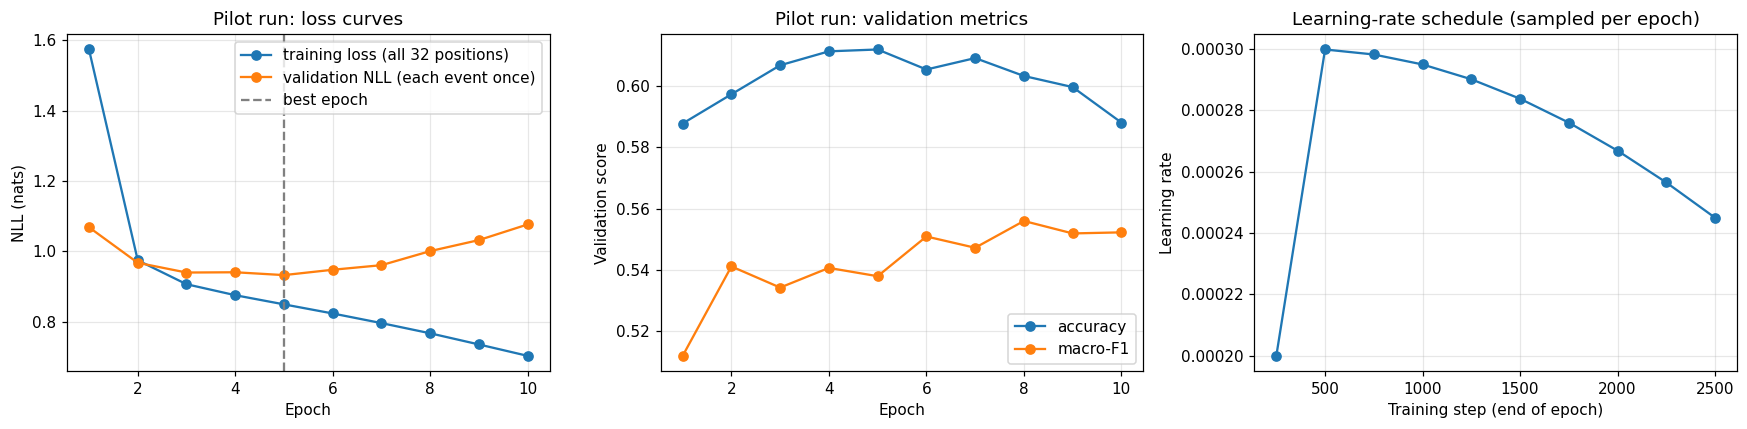

,epoch,step,learning_rate,train_loss,val_nll,val_accuracy,val_macro_f1,mean_gradient_norm,clipped_fraction,epoch_seconds
0,1,250,0.0002,1.5735,1.0682,0.5878,0.5118,1.9921,0.892,10.0396
1,2,500,0.0003,0.9744,0.9672,0.5974,0.5411,1.8421,0.924,7.8769
2,3,750,0.0003,0.9063,0.9395,0.6069,0.5342,1.4618,0.884,9.1780
3,4,1000,0.0003,0.8751,0.9403,0.6114,0.5406,1.2635,0.776,9.0787
4,5,1250,0.0003,0.8491,0.9322,0.6120,0.5379,1.3336,0.872,8.3661
5,6,1500,0.0003,0.8232,0.9474,0.6055,0.5509,1.3917,0.908,9.3727
6,7,1750,0.0003,0.7958,0.9604,0.6092,0.5472,1.5427,1.000,8.8507
7,8,2000,0.0003,0.7668,1.0005,0.6034,0.5559,1.6450,1.000,8.6273
8,9,2250,0.0003,0.7351,1.0318,0.5997,0.5519,1.8448,1.000,9.5351
9,10,2500,0.0002,0.7026,1.0763,0.5881,0.5522,1.9604,1.000,9.2343


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(pilot_history["epoch"], pilot_history["train_loss"], marker="o", label="training loss (all 32 positions)")
axes[0].plot(pilot_history["epoch"], pilot_history["val_nll"], marker="o", label="validation NLL (each event once)")
axes[0].axvline(pilot["best_epoch"], color="grey", linestyle="--", label="best epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("NLL (nats)")
axes[0].set_title("Pilot run: loss curves")
axes[0].legend()
axes[1].plot(pilot_history["epoch"], pilot_history["val_accuracy"], marker="o", label="accuracy")
axes[1].plot(pilot_history["epoch"], pilot_history["val_macro_f1"], marker="o", label="macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation score")
axes[1].set_title("Pilot run: validation metrics")
axes[1].legend()
axes[2].plot(pilot_history["step"], pilot_history["learning_rate"], marker="o")
axes[2].set_xlabel("Training step (end of epoch)")
axes[2].set_ylabel("Learning rate")
axes[2].set_title("Learning-rate schedule (sampled per epoch)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_pilot_curves.png", bbox_inches="tight")
plt.show()
pilot_history.round(4)

**What the figure shows.** Left: training loss and validation NLL per epoch for the pilot run (base configuration, seed 0). Middle: validation accuracy and macro-F1. Right: the learning rate at the end of each epoch.

**Observation.** Validation NLL reaches its minimum at epoch 5 (0.9322) and rises afterwards, to 1.0763 at epoch 10, while the training loss keeps falling (0.8491 at epoch 5, 0.7026 at epoch 10). Early stopping ended the run after epoch 10. The best epoch lies well inside the 30-epoch budget, so the budget was kept at 30. The gradient norm exceeded the clipping value of 1.0 in most steps (78–100% of steps per epoch), so gradient clipping was active for the majority of updates.

**Interpretation.** The model starts to overfit the training matches after about five epochs at this learning rate. The checkpoint with the lowest validation NLL is kept, so later results refer to the best epoch of each run, not to the overfitted end state. Macro-F1 continues to fluctuate between 0.54 and 0.56 after epoch 5, which indicates that the rise in NLL comes mainly from over-confident probabilities rather than from a loss of class coverage.

**Note on scale.** Training loss is averaged over all 32 positions of each window, including early positions with little history, while validation NLL scores each event once with maximal history. The two curves are therefore not on exactly the same scale.

**What cannot be concluded.** One seed at one setting shows that training works and where overfitting starts; it does not show which setting is best.

## 5. Learning-rate and weight-decay search

**Search space and budget (fixed in advance).**

| Stage | Runs | Purpose |
|---|---|---|
| H1 | learning rate ∈ {1e-4, 3e-4, 1e-3, 3e-3}, seed 0, weight decay 0.1 | find the right order of magnitude |
| H2 | weight decay 0.01 at the two best H1 learning rates, seed 0 | check whether weaker regularisation helps |
| H3 | the two best configurations of H1+H2, seeds 1 and 2 | separate real differences from seed luck |

**Selection metric:** mean validation NLL over seeds 0, 1, 2. **Tie rule:** if the better finalist does not beat the other beyond noise (Section 2.5), choose the one with the lower learning rate (more stable); if both share a learning rate, keep the starting weight decay of 0.1 (no evidence for changing it). The pilot run is the H1 run at 3e-4 and is reused.

In [12]:
search_results = {}
for learning_rate in [1e-4, 3e-4, 1e-3, 3e-3]:
    run_dir, result = run(transformer_config(0, learning_rate, 0.1, max_epochs=EPOCH_BUDGET))
    search_results[(learning_rate, 0.1, 0)] = run_dir

h1_table = pd.DataFrame([{"learning rate": key[0], "weight decay": key[1],
                          "val NLL": analysis.load_final_results(run_dir)["val_metrics"]["nll"]}
                         for key, run_dir in search_results.items()]).sort_values("val NLL")
best_two_rates = h1_table["learning rate"].head(2).tolist()
print("H1 (seed 0):")
print(h1_table.to_string(index=False))

for learning_rate in best_two_rates:
    run_dir, result = run(transformer_config(0, learning_rate, 0.01, max_epochs=EPOCH_BUDGET))
    search_results[(learning_rate, 0.01, 0)] = run_dir

[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  1 | train loss 1.8477 | val NLL 1.2902 | val acc 0.5612 | val macro-F1 0.4079 | 9s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  2 | train loss 1.1053 | val NLL 1.0176 | val acc 0.6003 | val macro-F1 0.5226 | 9s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  3 | train loss 0.9648 | val NLL 0.9700 | val acc 0.6046 | val macro-F1 0.5360 | 10s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  4 | train loss 0.9210 | val NLL 0.9504 | val acc 0.6093 | val macro-F1 0.5314 | 10s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  5 | train loss 0.8966 | val NLL 0.9424 | val acc 0.6082 | val macro-F1 0.5355 | 9s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0001_wd0.1_s0] epoch  6 | train loss 0.8797 | val NLL 0.9452 | val acc 0.6030 | val macro-F1 0.5460 | 10s
[transformer_

In [13]:
seed0_rows = []
for (learning_rate, weight_decay, seed), run_dir in search_results.items():
    if seed == 0:
        result = analysis.load_final_results(run_dir)
        seed0_rows.append({"learning rate": learning_rate, "weight decay": weight_decay,
                           "val NLL": result["val_metrics"]["nll"], "best epoch": result["best_epoch"],
                           "diverged": result["diverged"]})
seed0_table = pd.DataFrame(seed0_rows).sort_values("val NLL")
finalists = [(row["learning rate"], row["weight decay"]) for _, row in seed0_table.head(2).iterrows()]
print("Seed-0 results (H1 + H2):")
print(seed0_table.to_string(index=False))
print("\nFinalists for H3:", finalists)

for learning_rate, weight_decay in finalists:
    for seed in [1, 2]:
        run_dir, result = run(transformer_config(seed, learning_rate, weight_decay, max_epochs=EPOCH_BUDGET))
        search_results[(learning_rate, weight_decay, seed)] = run_dir

Seed-0 results (H1 + H2):
 learning rate  weight decay  val NLL  best epoch  diverged
        0.0003          0.01 0.930761           5     False
        0.0003          0.10 0.932227           5     False
        0.0010          0.10 0.934598           3     False
        0.0010          0.01 0.934768           3     False
        0.0001          0.10 0.937135           7     False
        0.0030          0.10 0.938815           3     False

Finalists for H3: [(0.0003, 0.01), (0.0003, 0.1)]
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.01_s1] epoch  1 | train loss 1.5781 | val NLL 1.0694 | val acc 0.5892 | val macro-F1 0.5126 | 10s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.01_s1] epoch  2 | train loss 0.9746 | val NLL 0.9605 | val acc 0.6042 | val macro-F1 0.5447 | 10s
[transformer_T100_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.01_s1] epoch  3 | train loss 0.9045 | val NLL 0.9436 | val acc 0.6059 | val macro-F1 0.5432 | 9s
[trans

In [14]:
finalist_runs = {}
for learning_rate, weight_decay in finalists:
    finalist_runs[(learning_rate, weight_decay)] = [search_results[(learning_rate, weight_decay, seed)] for seed in [0, 1, 2]]

finalist_rows = []
for key, run_dirs in finalist_runs.items():
    summary = analysis.seed_summary(run_dirs)
    finalist_rows.append({"learning rate": key[0], "weight decay": key[1],
                          "mean val NLL": summary["val NLL"].mean(), "seed SD": summary["val NLL"].std(ddof=1),
                          "per-seed val NLL": [round(v, 4) for v in summary["val NLL"]],
                          "mean macro-F1": summary["val macro-F1"].mean()})
finalist_table = pd.DataFrame(finalist_rows).sort_values("mean val NLL").reset_index(drop=True)

better_key = (finalist_table.loc[0, "learning rate"], finalist_table.loc[0, "weight decay"])
other_key = (finalist_table.loc[1, "learning rate"], finalist_table.loc[1, "weight decay"])
comparison = analysis.compare_conditions(finalist_runs[better_key], finalist_runs[other_key], targets, match_ids)
if comparison["a_better_beyond_noise"]:
    selected = better_key
    reason = "better finalist beats the other beyond noise"
else:
    if better_key[0] != other_key[0]:
        selected = min([better_key, other_key], key=lambda key: key[0])
        reason = "finalists not distinguishable beyond noise -> lower learning rate (tie rule)"
    else:
        selected = better_key if better_key[1] == 0.1 else other_key
        reason = "finalists not distinguishable beyond noise and share a learning rate -> starting weight decay 0.1 (tie rule)"
print(finalist_table.to_string(index=False))
print("\nComparison of finalists:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in comparison.items()})
print(f"\nSELECTED: learning rate {selected[0]:g}, weight decay {selected[1]:g}  ({reason})")

search_table = pd.DataFrame([{"learning rate": key[0], "weight decay": key[1], "seed": key[2],
                              **{k: v for k, v in analysis.load_final_results(run_dir)["val_metrics"].items() if k != "per_class_f1"},
                              "best epoch": analysis.load_final_results(run_dir)["best_epoch"]}
                             for key, run_dir in search_results.items()])
search_table.to_csv(RESULTS_DIR / "04_search_table.csv", index=False)
selection_record = {"learning_rate": selected[0], "weight_decay": selected[1], "epoch_budget": EPOCH_BUDGET,
                    "reason": reason, "comparison_of_finalists": comparison,
                    "selection_metric": "mean validation NLL over seeds 0-2",
                    "base_encoding": BASE_ENCODING, "run_mode": RUN_MODE}
training.save_json(RESULTS_DIR / "04_selected_hyperparameters.json", selection_record)

 learning rate  weight decay  mean val NLL  seed SD         per-seed val NLL  mean macro-F1
        0.0003          0.10      0.930349 0.003223 [0.9322, 0.9266, 0.9322]       0.545772
        0.0003          0.01      0.931808 0.001840 [0.9308, 0.9307, 0.9339]       0.547958

Comparison of finalists: {'n_events': 68003, 'nll_a_mean': 0.9303, 'nll_a_seed_sd': 0.0032, 'nll_b_mean': 0.9318, 'nll_b_seed_sd': 0.0018, 'difference_a_minus_b': -0.0015, 'difference_ci_low': -0.0022, 'difference_ci_high': -0.0007, 'seeds_completely_separated': False, 'a_better_beyond_noise': False}

SELECTED: learning rate 0.0003, weight decay 0.1  (finalists not distinguishable beyond noise and share a learning rate -> starting weight decay 0.1 (tie rule))


**RESULT.** On seed 0, validation NLL ranges from 0.9308 (learning rate 3e-4, weight decay 0.01) to 0.9388 (learning rate 3e-3). A learning rate of 3e-4 gives the lowest NLL with both weight-decay values; the higher rates (1e-3, 3e-3) reach their best epoch earlier (epoch 3) and at a higher NLL. No run diverged.

The two finalists share the learning rate 3e-4. Over seeds 0–2, weight decay 0.1 gives 0.9303 (seed SD 0.0032) and weight decay 0.01 gives 0.9318 (seed SD 0.0018). The difference is −0.0015 nats with a 95% CI of −0.0022 to −0.0007, so the bootstrap interval excludes zero, but the per-seed results overlap (seed values 0.9322, 0.9266, 0.9322 against 0.9308, 0.9307, 0.9339). The difference therefore does not meet the decision rule, and the tie rule keeps the starting value, weight decay 0.1.

**Interpretation.** Within the searched range, the choice of learning rate and weight decay changes validation NLL by less than 0.01 nats. The two finalists are not distinguishable given the variation between seeds. The selected setting (learning rate 3e-4, weight decay 0.1) is kept fixed for all later architecture comparisons, so those comparisons are not confounded by re-tuning.

**Limitation.** The search was carried out for the base architecture (4 layers, 4 heads, K = 32, T100) only. Configurations that would prefer different settings may be slightly disadvantaged in notebook 05.

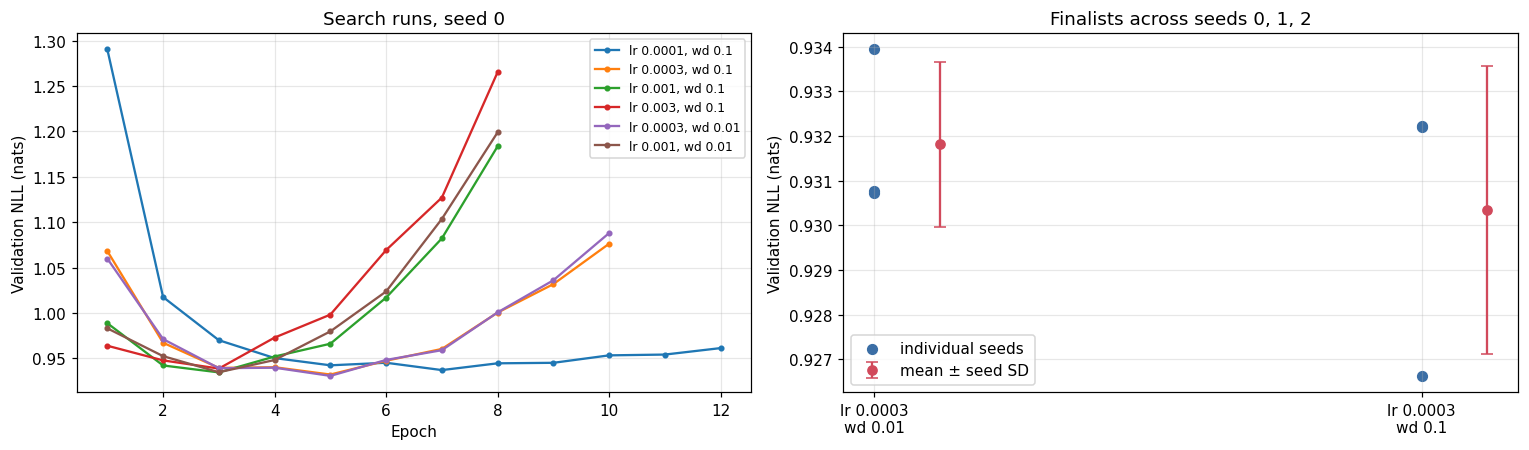

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for key, run_dir in search_results.items():
    if key[2] != 0:
        continue
    history = analysis.load_history(run_dir)
    axes[0].plot(history["epoch"], history["val_nll"], marker=".", label=f"lr {key[0]:g}, wd {key[1]:g}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Search runs, seed 0")
axes[0].legend(fontsize=8)

for position, (key, run_dirs) in enumerate(finalist_runs.items()):
    values = analysis.seed_summary(run_dirs)["val NLL"].to_numpy()
    axes[1].scatter(np.full(len(values), position), values, s=40, label="individual seeds" if position == 0 else None, color="#3b6ea5")
    axes[1].errorbar(position + 0.12, values.mean(), yerr=values.std(ddof=1), fmt="o", color="#d1495b", capsize=4,
                     label="mean ± seed SD" if position == 0 else None)
axes[1].set_xticks(range(len(finalist_runs)))
axes[1].set_xticklabels([f"lr {k[0]:g}\nwd {k[1]:g}" for k in finalist_runs])
axes[1].set_ylabel("Validation NLL (nats)")
axes[1].set_title("Finalists across seeds 0, 1, 2")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_search_curves_and_seeds.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: validation NLL per epoch for every seed-0 search run. Right: the three seeds of each finalist (blue) with mean ± standard deviation (red).

**Observation.** All search runs follow the same pattern: a steep drop over the first two to three epochs, a minimum, then a rise. Higher learning rates reach the minimum earlier. On the right, the seeds of the two finalists overlap, and the spread between seeds is of the same size as the difference between the finalists.

**Purpose of the figure.** It shows the effect of the learning rate on training dynamics next to the seed-to-seed variation, which is what the decision rule compares.

**What cannot be concluded.** Three seeds give only a rough estimate of seed variability; the standard deviation itself is uncertain.

## 6. MLP baseline B4

B4 uses the selected weight decay and a reduced learning-rate search: the selected rate and one grid step on either side (÷3, ×3), seed 0; the best is then run with seeds 1 and 2. It is compared with the base Transformer (same encoding, seeds 0–2) using the rule of Section 2.5.

In [16]:
def mlp_config(seed, learning_rate, weight_decay, encoding=BASE_ENCODING, max_epochs=EPOCH_BUDGET):
    return {"model_type": "mlp", "encoding": encoding, "possession_features": "pre_action",
            "context_length": 32, "stride": 8, "seed": seed,
            "model": {"n_layers": 0, "n_heads": 0, "d_model": 128, "d_ff": 0, "hidden": 512, "n_previous": 3},
            "training": {"learning_rate": learning_rate, "weight_decay": weight_decay, "max_epochs": max_epochs}}

selected_lr, selected_wd = selected
mlp_rates = [selected_lr / 3, selected_lr, selected_lr * 3]
mlp_seed0 = {}
for learning_rate in mlp_rates:
    run_dir, result = run(mlp_config(0, learning_rate, selected_wd))
    mlp_seed0[learning_rate] = result["val_metrics"]["nll"]
best_mlp_rate = min(mlp_seed0, key=mlp_seed0.get)
print("B4 seed-0 validation NLL by learning rate:", {f"{k:g}": round(v, 4) for k, v in mlp_seed0.items()},
      "-> selected", f"{best_mlp_rate:g}")

mlp_runs = []
for seed in [0, 1, 2]:
    run_dir, result = run(mlp_config(seed, best_mlp_rate, selected_wd))
    mlp_runs.append(run_dir)
transformer_runs = finalist_runs[selected] if selected in finalist_runs else [
    run(transformer_config(seed, selected_lr, selected_wd, max_epochs=EPOCH_BUDGET))[0] for seed in [0, 1, 2]]

b4_comparison = analysis.compare_conditions(transformer_runs, mlp_runs, targets, match_ids)
baseline_file = PROJECT_DIR / "results" / "baselines_validation.json"      # written by notebook 02
with open(baseline_file) as handle:
    non_neural = {row["baseline"]: row["val NLL"] for row in json.load(handle)["table"]}

summary_rows = [{"model": name, "val NLL (mean over seeds)": value, "seeds": 1} for name, value in non_neural.items()
                if "original possession" not in name]
summary_rows.append({"model": "B4 MLP (current + 3 previous events)", "val NLL (mean over seeds)": b4_comparison["nll_b_mean"], "seeds": 3})
summary_rows.append({"model": "Transformer (base config, T100)", "val NLL (mean over seeds)": b4_comparison["nll_a_mean"], "seeds": 3})
development_table = pd.DataFrame(summary_rows).set_index("model").round(4)
print(development_table)
print("\nTransformer vs B4:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in b4_comparison.items()})
training.save_json(RESULTS_DIR / "04_b4_comparison.json", {"mlp_learning_rates": mlp_seed0, "selected_mlp_lr": best_mlp_rate,
                                                           "comparison_transformer_minus_mlp": b4_comparison})

[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  1 | train loss 1.8741 | val NLL 1.3257 | val acc 0.4888 | val macro-F1 0.3424 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  2 | train loss 1.2410 | val NLL 1.1725 | val acc 0.5283 | val macro-F1 0.4558 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  3 | train loss 1.1221 | val NLL 1.0900 | val acc 0.5579 | val macro-F1 0.4843 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  4 | train loss 1.0593 | val NLL 1.0520 | val acc 0.5709 | val macro-F1 0.5005 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  5 | train loss 1.0207 | val NLL 1.0299 | val acc 0.5770 | val macro-F1 0.5035 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  6 | train loss 0.9903 | val NLL 1.0180 | val acc 0.5798 | val macro-F1 0.5147 | 4s
[mlp_T100_pre_action_L0_H0_D128_F0_K32_g-all_lr0.0001_wd0.1_s0] epoch  7 | t

**RESULT.** For B4, the learning rate 9e-4 gave the lowest seed-0 validation NLL (0.971, against 0.976 at 3e-4 and 0.980 at 1e-4). Over seeds 0–2, B4 reaches a validation NLL of 0.9711, against 0.9303 for the base Transformer. The difference is −0.0407 nats (95% CI −0.0453 to −0.0364), and every Transformer seed is better than every B4 seed, so the Transformer is better than B4 beyond noise. Both are well below the logistic-regression baseline B3 (1.0522).

**Interpretation.** A fixed history of the current and three previous events (B4) already improves substantially on the current event alone (B3). Attention over the full 32-event window improves on it further. The result indicates that the Transformer uses information in the sequence that a short fixed history does not provide, which supports studying the attention mechanism in the later mechanistic analysis.

**Limitations.** The selected B4 learning rate is the largest value in its search grid, so a larger rate might have improved B4 slightly. The comparison is made on validation data with the base architecture; the final baseline comparison with the frozen configuration is reported in notebook 06.

## 7. Summary

* The pilot run reaches its best validation NLL at epoch 5 and then overfits; a 30-epoch budget with early stopping (patience 5) is sufficient.
* The learning rate 3e-4 gives the lowest validation NLL in the search. The two weight-decay values are not distinguishable beyond noise, and weight decay 0.1 is kept.
* The base Transformer (validation NLL 0.9303) is better than the MLP baseline B4 (0.9711) beyond noise, and both are better than logistic regression (1.0522).
* The learning rate and weight decay are fixed from this point on.